In [146]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from numba import njit
from scipy.signal import convolve2d
from tqdm import tqdm

# Simulación Monte Carlo del modelo de Ising con el algoritmo de Metropolis

A lo largo de este jupyter notebook, se va a presentar una implementación del algoritmo de Metropolis Hasting para realizar una simulación de la evolución de una red cuadrada de 50x50 de espines semi enteros (1/2). Para ello, se van a definir distintas funciones auxiliares y se presentaran los gráficos relacionados con la evolución de la magnetización y la energía de la grilla. 

## Paso 1: Inicialización de la grilla de espines 1/2

En esta primera parte, se va a inicializar una grilla de 50x50 con orientaciones completamente aleatorias para los espines. La idea para este caso preliminar será comenzar con una grilla que se encuentre en un estado energético más elevado que el de equilibrio. Por ello, se va a construir una grilla de tal forma que el 75% de los espines apunten hacia arriba y el 25% hacia abajo. Para ello, se genera una grilla donde se muestrea un avalor aleatorio entre 0 y 1 de una distribución aleatoria uniforme. De esta, se construye una grilla final de tal forma que toma el valor 1 o -1 si se cumplen las siguientes condiciones:
$$
s_{i,j} =
\begin{cases}
    1 & \text{si } \text{grilla random}_{i,j} \leq 0.75 \\
    -1  & \text{si } \text{grilla random}_{i,j} > 0.75 \\
\end{cases}
$$

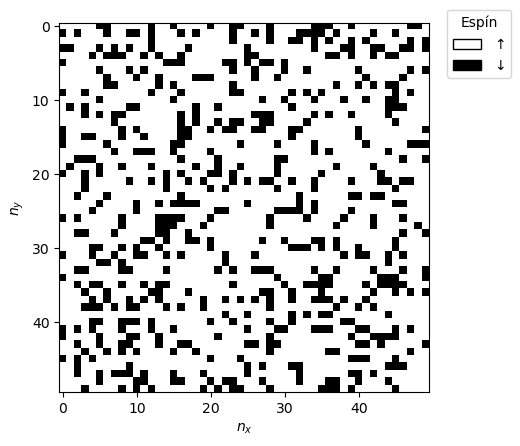

In [147]:
N = 50
prop_spin_up = 0.75
grilla_random = np.random.rand(N,N)
grilla_init = np.where(grilla_random < prop_spin_up, 1, -1)
plt.imshow(grilla_init, cmap='gray')
legend_elements = [
    Patch(facecolor="white", edgecolor="black", label=r"$\uparrow$"),
    Patch(facecolor="black", edgecolor="black", label=r"$\downarrow$")
]
plt.legend(handles=legend_elements, loc=(1.05,0.85), title = "Espín")
plt.xlabel(r"$n_x$")
plt.ylabel(r"$n_y$")
plt.show()

## Paso 2: Evolución del sistema por medio de Metropolis Hasting: Cambio de un espín y aceptación de cambio

A continuación, se presenta la implementación del algoritmo de Metropolis Hasting para los pasos de evolución del sistema. Para garantizar condiciones de frontera periódicas, se saca a cada posición de la grilla su módulo con N (i%N), de modo que si se evalua en una de las fronteras, el vecino en i/j = N+1 = 1 (0 en el caso de python, pues los indices empiezan desde 0). La energía del sistema despues de un paso será igual a $E_{[k+1]}=E_{[k]}+\Delta E$ si el cambio es aceptado y $E_{[k+1]}=E_{[k]}$ si no.

El verdadero gasto computacional está en determinar la energía inicial del sistema. El algoritmo más simple para ello, sería realizar la suma sobre cada posición de la red con sus primeros vecinos. Esto implicaría realizar un for loop de complejidad $\mathcal{O}(N^2)$, lo cuál para redes muy grandes crece muy rápido. Por lo tanto, se va a utilizar una convolución de toda la grilla con un kernel de primeros vecinos. Dicho algoritmo de convolución escala en complejidad como $\mathcal{O}(N^2\log(N))$ lo cuál es mucho más eficiente. 

In [182]:
@njit
def metropolis_step(grilla, beta, i, j,J):
    N = grilla.shape[0]
    spin_actual = grilla[i, j]
    spin_nuevo = -spin_actual
    delta_E = 2*J* spin_actual * (
        grilla[(i + 1) % N, j] +
        grilla[(i - 1) % N, j] +
        grilla[i, (j + 1) % N] +
        grilla[i, (j - 1) % N]
        )
    if delta_E <= 0 or np.random.rand() < np.exp(-beta * delta_E):
        grilla[i, j] = spin_nuevo
        delta_E = delta_E
    else:
        delta_E = 0
    return grilla, delta_E

In [ ]:
def get_init_E(grilla, J):
    kernel = np.array([[0, 1, 0],
                        [1, 0, 1],
                        [0, 1, 0]])
    convolucion = convolve2d(grilla, kernel, mode='same', boundary='wrap')
    E = -J * np.sum(grilla * convolucion) / 2 #dividir entre 2 para no contar dos veces las interacciones
    return E

### Paso 3: Evolución del sistema para mútliples pasos y gráficas de energía y magnetización
Por último, se define una nueva función que se encargara de realizar la evolución del sistema en un número determinado de épocas. esta función retornará un array con las energías y magnetizaciones para cada época, las cuáles serán utilizadas posteriormente para tomar promedios y construir gráficas de energía contra temperatura y de **magnetización** contra temperatura.

In [187]:
def evolucion_metropolis(grilla, beta, J, epochs):
    N = grilla.shape[0]
    E = get_init_E(grilla, J)
    M = np.sum(grilla)/(N**2)
    energias = np.zeros(epochs+1)
    energias[0] = E
    magnetizaciones = np.zeros(epochs+1)
    magnetizaciones[0] = M

    for step in range(epochs):
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)
        grilla, delta_E = metropolis_step(grilla, beta, i, j,J)
        E += delta_E
        M = np.sum(grilla)/(N**2)
        
        energias[step+1] = E
        magnetizaciones[step+1] = M
    
    return grilla, energias, magnetizaciones

In [199]:
Temp = 293.15 #K
J = 15000 #mueV
Kb =  86.17333262 #mueV/K
grilla_final, energias, magnetizaciones = evolucion_metropolis(grilla_init.copy(), 1/(Kb*Temp), J, epochs=int(1e6))


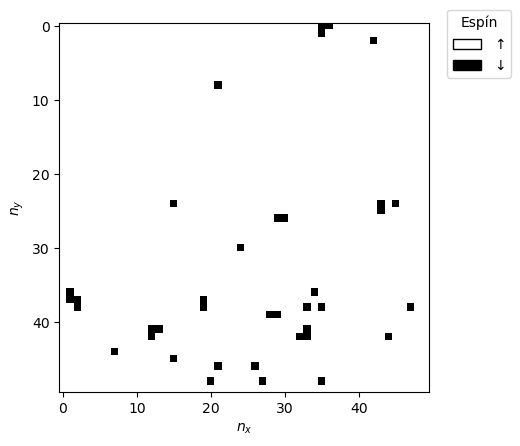

In [200]:
plt.imshow(grilla_final, cmap='gray')
legend_elements = [
    Patch(facecolor="white", edgecolor="black", label=r"$\uparrow$"),
    Patch(facecolor="black", edgecolor="black", label=r"$\downarrow$")
]
plt.legend(handles=legend_elements, loc=(1.05,0.85), title = "Espín")
plt.xlabel(r"$n_x$")
plt.ylabel(r"$n_y$")
plt.show()

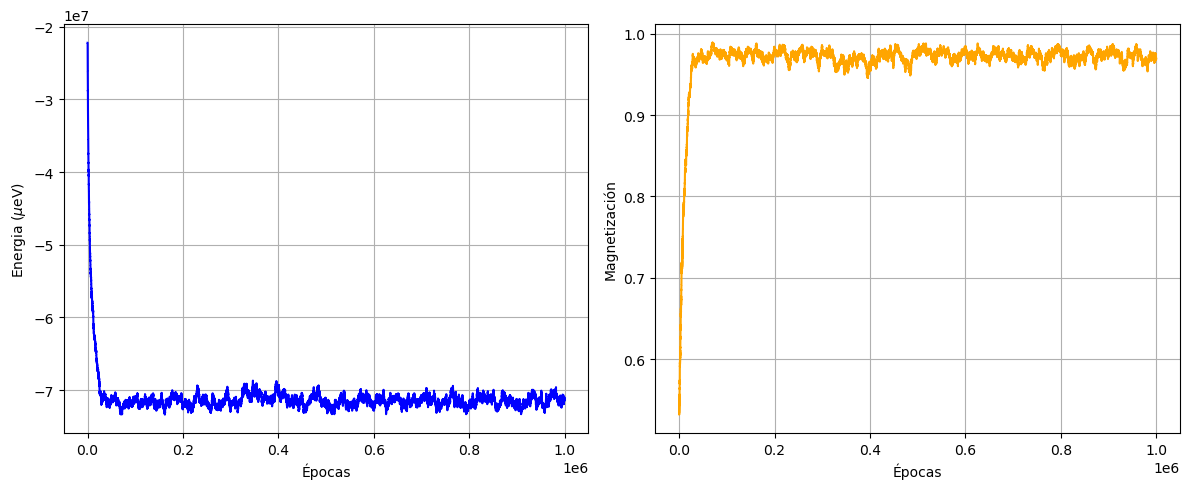

In [201]:
# Grafica de energía y magnetización a lo largo del tiempo
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(energias, color='blue')
plt.xlabel('Épocas')
plt.ylabel(r'Energia ($\mu$eV)')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(magnetizaciones, color='orange')
plt.xlabel('Épocas')
plt.ylabel('Magnetización')
plt.grid(True)
plt.tight_layout()
plt.show()

In [197]:
Temp = 395 #K
J = 15000 #mueV
Kb =  86.17333262 #mueV/K
grilla_final, energias, magnetizaciones = evolucion_metropolis(grilla_init.copy(), 1/(Kb*Temp), J, epochs=int(1e6))

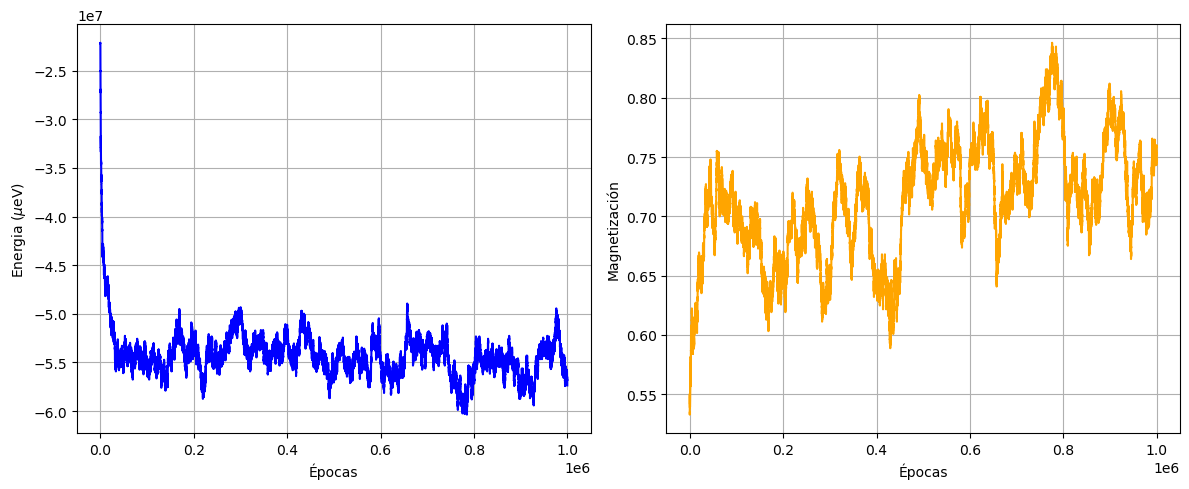

In [198]:
# Grafica de energía y magnetización a lo largo del tiempo
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(energias, color='blue')
plt.xlabel('Épocas')
plt.ylabel(r'Energia ($\mu$eV)')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(magnetizaciones, color='orange')
plt.xlabel('Épocas')
plt.ylabel('Magnetización')
plt.grid(True)
plt.tight_layout()
plt.show()

In [207]:
Temp = 450 #K
J = 15000 #mueV
Kb =  86.17333262 #mueV/K
grilla_final, energias, magnetizaciones = evolucion_metropolis(grilla_init.copy(), 1/(Kb*Temp), J, epochs=int(1e6))

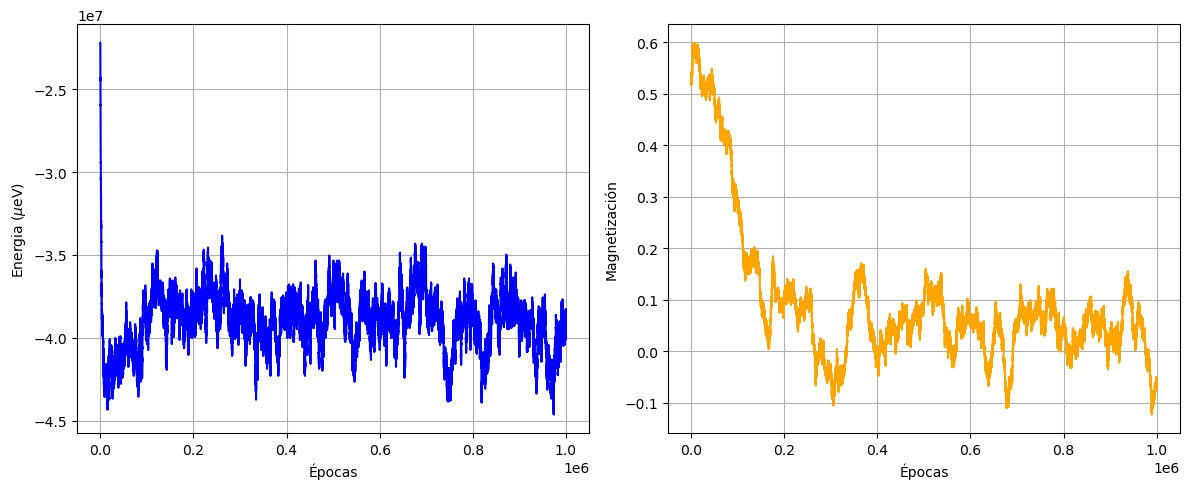

In [208]:
# Grafica de energía y magnetización a lo largo del tiempo
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(energias, color='blue')
plt.xlabel('Épocas')
plt.ylabel(r'Energia ($\mu$eV)')
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(magnetizaciones, color='orange')
plt.xlabel('Épocas')
plt.ylabel('Magnetización')
plt.grid(True)
plt.tight_layout()
plt.show()

### Paso 4: Variar temperatura y graficar magnetización contra temperatura y energía contra temperatura.

Con esto, se procede ahora a realizar un loop que recorra para distintos valores de temperatura, haga los pasos de Metropolis para 1e6 épocas y tome el promedio de energía y magnetización para las últimas 1e5, en dónde se supone que debería de estabilizarse. Con esto, se consturyen los gráficos de magnetización contra temperatura, energía contra temperatura y varianza de la energía contra temperatura. 

In [192]:
def temperature_sweep(grilla, T_values, J, epochs):
    Kb =  86.17333262 #mueV/K
    avg_E = np.zeros(len(T_values))
    std_E = np.zeros(len(T_values))
    avg_M = np.zeros(len(T_values))
    grilla_copy = grilla.copy()
    for t in tqdm(range(len(T_values)), desc="Barrido de Temperatura"):
        beta = 1 / (Kb * T_values[t])
        _, energias, magnetizaciones = evolucion_metropolis(grilla_copy, beta, J, epochs)
        avg_E[t] = np.mean(energias[-100000:])  # Promedio de las últimas 100000 energías
        std_E[t] = np.std(energias[-100000:])  # Desviación estándar de las últimas 100000 energías
        avg_M[t] = np.mean(magnetizaciones[-100000:])# Promedio de las últimas 100000 magnetizaciones

    return avg_E, avg_M, std_E

In [193]:
J = 15000 #mueV
T_values = np.linspace(200, 500, 300)  # Temperaturas de 200 K a 500 K
E_eq, M_eq, std_E = temperature_sweep(grilla_init, T_values, J, epochs=int(1e6))

Barrido de Temperatura: 100%|██████████| 300/300 [28:38<00:00,  5.73s/it]


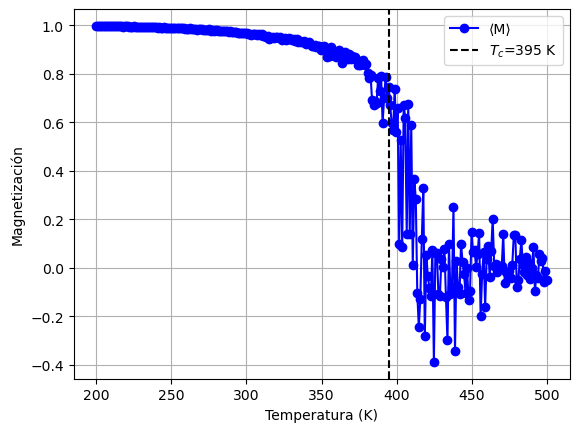

In [204]:


# Magnwetización contra Temperatura
plt.plot(T_values, M_eq, 'o-', color='blue', label='⟨M⟩')
plt.xlabel('Temperatura (K)')
plt.ylabel('Magnetización')
plt.axvline(x=395, color='k', linestyle='--', label=r'$T_c$=395 K')
plt.grid(True)
plt.legend()

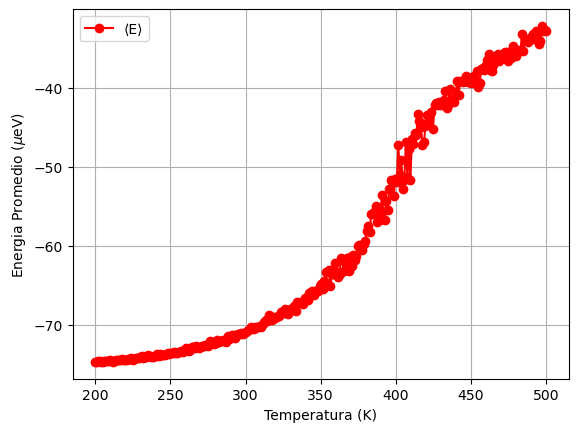

In [205]:
# Energia contra temperatura
plt.plot(T_values, E_eq*1e-6, 'o-', color='red', label='⟨E⟩')
plt.xlabel('Temperatura (K)')
plt.ylabel(r'Energia Promedio ($\mu$eV)')
plt.grid(True)
plt.legend()



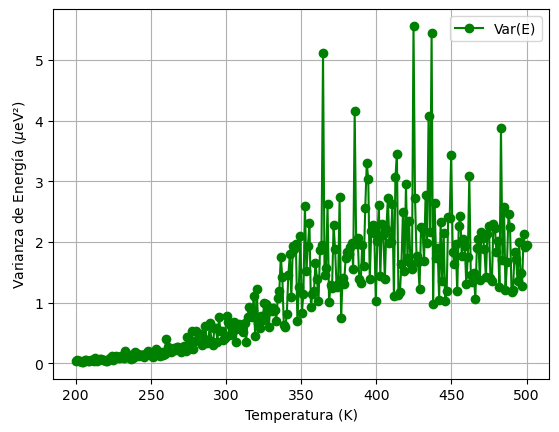

In [206]:
#Varianca de energía contra temperatura
plt.plot(T_values, (std_E*1e-6)**2, 'o-', color='green', label='Var(E)')
plt.xlabel('Temperatura (K)')
plt.ylabel(r'Varianza de Energía ($\mu$eV²)')

plt.grid(True)
plt.legend()


plt.show()